# 実験3 (ex003): 感度分析・曲率クリッピングアブレーション・計算効率＆スケーラビリティ解析

本実験では、**10種類の乱数シード（`42`〜`51`）** を用いて以下の4つの詳細解析を実施する。
1. **実験 3A (慣性係数 $\mu / \mu_{\max}$ の感度分析)**: MCLR および CompactCNN において $\mu, \mu_{\max} \in \{0.1, 0.2, \dots, 0.9\}$ を 0.1 刻みで変化させ、`MoQ` 系（`FedSSO-MoQ`, `FedSSO-AdaMoQ`）と `NAQ` 系（`FedSSO-NAQ`, `FedSSO-AdaNAQ`）および基準線 `FedSSO`（$\mu=0$）を比較
2. **実験 3B (記憶制限履歴数 $m$ の影響分析)**: MCLR における `FedSSO-LBFGS`, `FedSSO-LNAQ`, `FedSSO-LMoQ` ($m \in \{2^0, 2^1, 2^2, 2^3, 2^4, 2^5\} = \{1, 2, 4, 8, 16, 32\}$) の比較
3. **実験 3C (正定値保証・曲率クリッピング $\lambda, \Lambda$ のアブレーション検証)**: 非凸 CompactCNN における `MoQ` 系・`NAQ` 系全 7 手法（`FedSSO`, `FedSSO-MoQ`, `FedSSO-LMoQ`, `FedSSO-MLMoQ`, `FedSSO-NAQ`, `FedSSO-LNAQ`, `FedSSO-MLNAQ`）に対する 4 条件の比較
4. **実験 3D (通信コスト・サーバ計算時間・理論スケーリング総合解析)**: `ex001`・`ex002` の実測結果と次元数 $d \in [10^3, 10^6]$ の理論計算量・メモリ比較

In [1]:
import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from utils import (
    DEFAULT_SEEDS,
    setup_japanese_matplotlib,
    get_runners,
    run_momentum_sensitivity_study,
    run_memory_size_study,
    run_curvature_ablation_study,
    compute_theoretical_scaling,
)

setup_japanese_matplotlib()
os.makedirs("../report/img", exist_ok=True)
os.makedirs("../datasets", exist_ok=True)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"使用デバイス: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

ex1_utils, ex2_model, ex2_utils = get_runners()
_, packed_mclr, X_tr_m, y_tr_m, X_te_m, y_te_m, _ = ex1_utils.load_and_partition_mnist(
    data_dir="../datasets", num_clients=20, beta=0.1, train_ratio=0.75, seed=42, device=device
)
_, packed_cnn, X_tr_c, y_tr_c, X_te_c, y_te_c = ex2_utils.load_and_partition_mnist_2d(
    data_dir="../datasets", num_clients=20, beta=0.1, train_ratio=0.75, seed=42, device=device
)
print("MCLR および CompactCNN データ分割の準備完了")

使用デバイス: cuda (NVIDIA GeForce RTX 4080)
MCLR および CompactCNN データ分割の準備完了


In [2]:
# 実験 3A: 慣性係数 mu / max_mu (0.1..0.9) の感度分析 (MoQ系 + NAQ系, 10シード)
df_3a = run_momentum_sensitivity_study(
    ex1_utils, ex2_model, ex2_utils,
    packed_mclr, X_tr_m, y_tr_m, X_te_m, y_te_m,
    packed_cnn, X_tr_c, y_tr_c, X_te_c, y_te_c,
    seeds=DEFAULT_SEEDS, rounds_mclr=100, rounds_cnn=100
)
df_3a.to_csv("../datasets/ex003_momentum_sensitivity.csv", index=False)
print("=== 実験 3A: 慣性係数感度分析 (10シード統計) ===")
df_3a

=== 実験 3A: 慣性係数感度分析 (10シード統計) ===


Exp 3A: Momentum Sensitivity (MoQ & NAQ): 100%|##########| 740/740 [18:42<00:00,  1.52s/it]


,Model,Algorithm,Param_Name,Param_Val,Acc_Ave,Acc_Med,Acc_Best,Acc_Worst,Acc_Std,Loss_Ave,Diverged_Seeds,Clip_Ave,Reset_Ave
0,MCLR,FedSSO,mu,0.0,0.922167,0.922407,0.923464,0.919865,0.000948,0.258789,0,0.0,0.0
1,MCLR,FedSSO-MoQ,mu,0.1,0.922378,0.922378,0.923007,0.921636,0.000435,0.259330,0,0.0,0.0
2,MCLR,FedSSO-MoQ,mu,0.2,0.921750,0.922036,0.922892,0.918780,0.001130,0.262643,0,0.0,0.0
3,MCLR,FedSSO-MoQ,mu,0.3,0.920973,0.921979,0.923349,0.912154,0.003168,0.264687,0,0.0,0.0
4,MCLR,FedSSO-MoQ,mu,0.4,0.921653,0.922150,0.923235,0.917752,0.001526,0.262268,0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
69,CompactCNN,FedSSO-AdaNAQ,max_mu,0.5,0.970699,0.976040,0.979838,0.943740,0.011335,0.081625,0,1.0,0.6
70,CompactCNN,FedSSO-AdaNAQ,max_mu,0.6,0.880466,0.975383,0.980466,0.097898,0.261435,0.307967,1,0.8,0.7
71,CompactCNN,FedSSO-AdaNAQ,max_mu,0.7,0.810555,0.966016,0.979724,0.110692,0.306315,0.485086,1,1.2,1.0
72,CompactCNN,FedSSO-AdaNAQ,max_mu,0.8,0.781112,0.952736,0.979724,0.097898,0.342828,0.564056,2,1.3,0.9


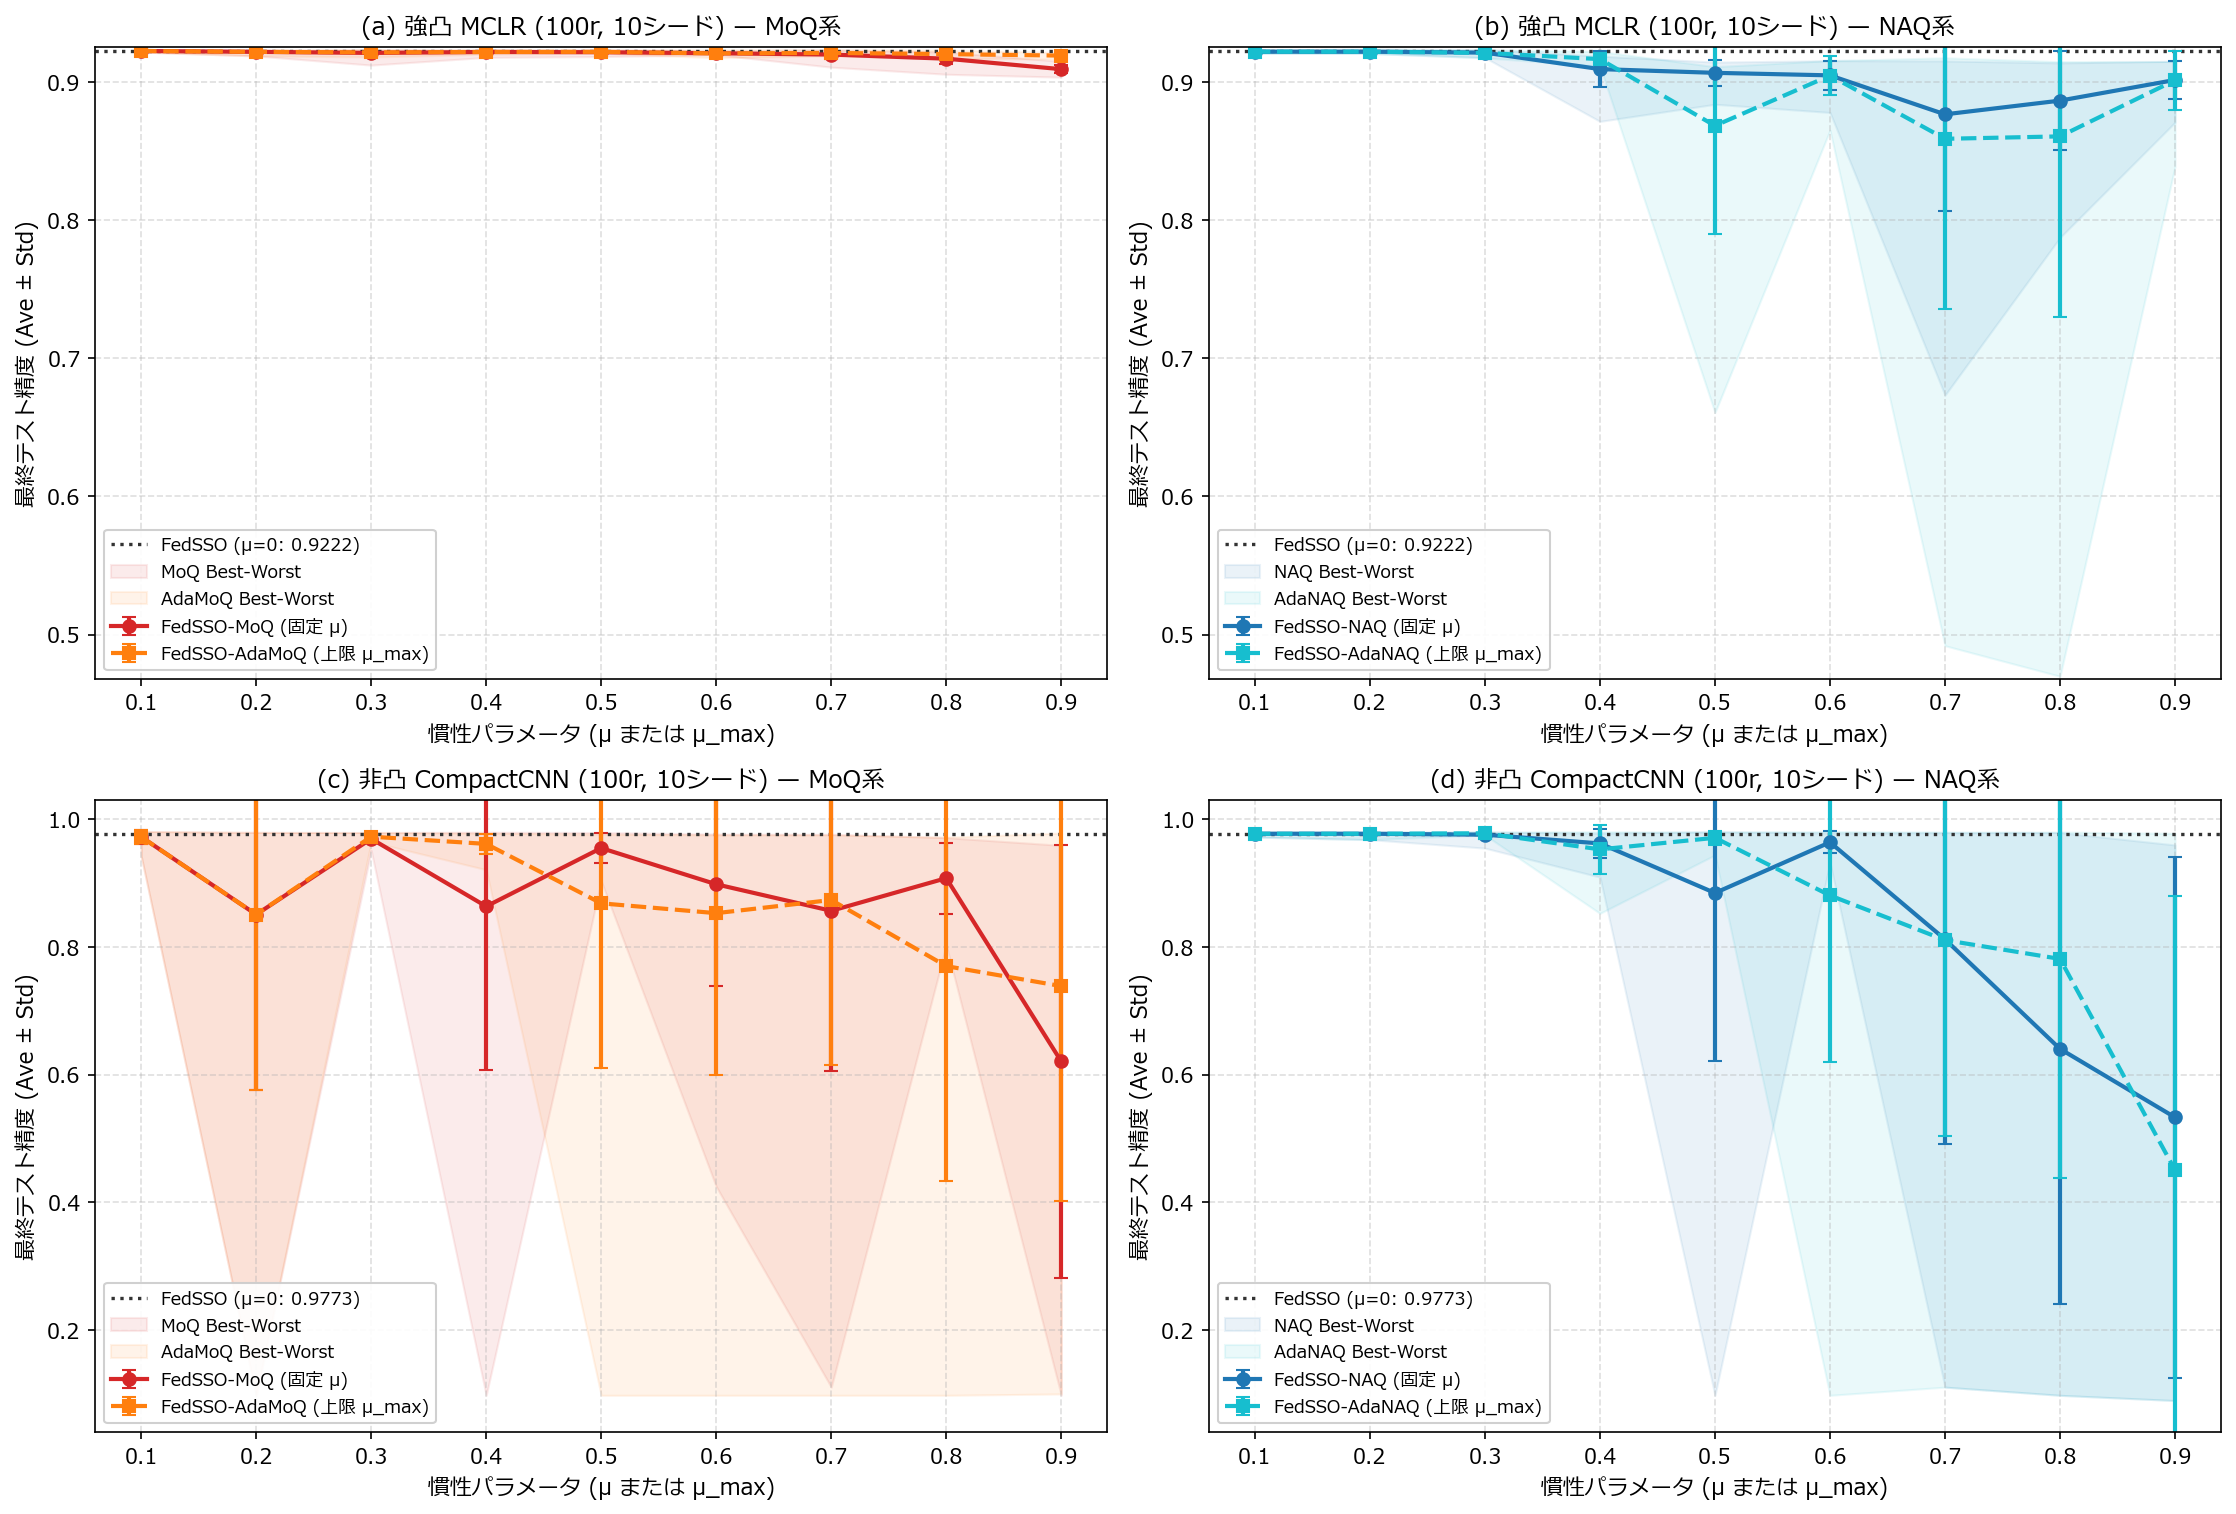

In [3]:
# 図1 (ex003): 慣性係数感度分析 2x2 比較図 (MoQ系 vs NAQ系, 0.1..0.9)
fig, axes = plt.subplots(2, 2, figsize=(15.0, 10.2))
xticks_3a = [round(0.1 * i, 1) for i in range(1, 10)]

row_specs = [
    ("MCLR", "強凸 MCLR (100r, 10シード)", (0.902, 0.9255)),
    ("CompactCNN", "非凸 CompactCNN (100r, 10シード)", (0.04, 1.03)),
]
col_specs = [
    ("MoQ系", "FedSSO-MoQ", "FedSSO-AdaMoQ", "#d62728", "#ff7f0e"),
    ("NAQ系", "FedSSO-NAQ", "FedSSO-AdaNAQ", "#1f77b4", "#17becf"),
]

for r_idx, (model_name, model_title, default_ylim) in enumerate(row_specs):
    sub_m = df_3a[df_3a["Model"] == model_name]
    base_acc = float(sub_m[sub_m["Algorithm"] == "FedSSO"]["Acc_Ave"].iloc[0])
    sub_curves = sub_m[sub_m["Algorithm"] != "FedSSO"]
    if model_name == "MCLR":
        y_lo = min(float(sub_curves["Acc_Worst"].min()) - 0.002, default_ylim[0])
        y_hi = max(float(sub_curves["Acc_Best"].max()) + 0.001, default_ylim[1])
        row_ylim = (y_lo, y_hi)
    else:
        row_ylim = default_ylim

    for c_idx, (fam_name, fixed_algo, ada_algo, col_f, col_a) in enumerate(col_specs):
        ax = axes[r_idx, c_idx]
        s_f = sub_m[sub_m["Algorithm"] == fixed_algo].sort_values("Param_Val")
        s_a = sub_m[sub_m["Algorithm"] == ada_algo].sort_values("Param_Val")

        ax.axhline(base_acc, color="#333333", linestyle=":", linewidth=1.6, label=f"FedSSO (μ=0: {base_acc:.4f})")
        ax.errorbar(s_f["Param_Val"], s_f["Acc_Ave"], yerr=s_f["Acc_Std"], marker="o", capsize=3.5, linewidth=2.0,
                    color=col_f, label=f"{fixed_algo} (固定 μ)")
        ax.errorbar(s_a["Param_Val"], s_a["Acc_Ave"], yerr=s_a["Acc_Std"], marker="s", capsize=3.5, linewidth=2.0,
                    color=col_a, linestyle="--", label=f"{ada_algo} (上限 μ_max)")
        ax.fill_between(s_f["Param_Val"], s_f["Acc_Worst"], s_f["Acc_Best"], color=col_f, alpha=0.09,
                        label=f"{fixed_algo.replace('FedSSO-', '')} Best-Worst")
        ax.fill_between(s_a["Param_Val"], s_a["Acc_Worst"], s_a["Acc_Best"], color=col_a, alpha=0.09,
                        label=f"{ada_algo.replace('FedSSO-', '')} Best-Worst")

        ax.set_title(f"({chr(97 + r_idx * 2 + c_idx)}) {model_title} — {fam_name}", fontsize=11.5)
        ax.set_xlabel("慣性パラメータ (μ または μ_max)", fontsize=10.5)
        ax.set_ylabel("最終テスト精度 (Ave ± Std)", fontsize=10.5)
        ax.set_xticks(xticks_3a)
        ax.set_ylim(row_ylim)
        ax.grid(True, linestyle="--", alpha=0.4)
        ax.legend(loc="lower left", fontsize=8.5, framealpha=0.92)

plt.tight_layout()
plt.savefig("../report/img/ex003_momentum_sensitivity.png", dpi=150, bbox_inches="tight")
plt.show()

In [4]:
# 実験 3B: 記憶制限履歴数 m in {1, 2, 4, 8, 16, 32} の影響分析 (MCLR, 150r, 10シード)
df_3b = run_memory_size_study(
    ex1_utils, packed_mclr, X_tr_m, y_tr_m, X_te_m, y_te_m,
    seeds=DEFAULT_SEEDS, rounds=150, m_values=(1, 2, 4, 8, 16, 32)
)
df_3b.to_csv("../datasets/ex003_memory_size.csv", index=False)
print("=== 実験 3B: 記憶制限履歴数 m (2^0..2^5) の影響 (MCLR, 150ラウンド, 10シード) ===")
df_3b

=== 実験 3B: 記憶制限履歴数 m (2^0..2^5) の影響 (MCLR, 150ラウンド, 10シード) ===


Exp 3B: Memory Size m (2^0..2^5): 100%|##########| 180/180 [01:29<00:00,  2.00it/s]


,Algorithm,m,Acc_Ave,Acc_Med,Acc_Best,Acc_Worst,Acc_Std,Loss_Ave,Total_Comm_Ave,Server_Time_ms,Server_Mem_MB,Clip_Ave
0,FedSSO-LBFGS,1,0.916478,0.916638,0.918380,0.914154,0.001425,0.290729,150.0,0.434832,0.179672,10.2
1,FedSSO-LBFGS,2,0.915924,0.915639,0.917581,0.915067,0.000847,0.292550,150.0,0.523771,0.239563,1.9
2,FedSSO-LBFGS,4,0.920414,0.920551,0.921864,0.917581,0.001097,0.274171,150.0,0.657056,0.359344,0.3
3,FedSSO-LBFGS,8,0.922521,0.922578,0.923749,0.921407,0.000723,0.262818,150.0,0.935890,0.598907,0.0
4,FedSSO-LBFGS,16,0.922213,0.922150,0.922949,0.921407,0.000616,0.260234,150.0,1.505864,1.078033,0.0
5,FedSSO-LBFGS,32,0.922207,0.922293,0.922949,0.920608,0.000707,0.259901,150.0,3.648154,2.036285,0.1
6,FedSSO-LNAQ,1,0.916164,0.916124,0.918380,0.912669,0.001811,0.306587,299.0,0.804533,0.239563,33.2
7,FedSSO-LNAQ,2,0.919043,0.919066,0.920379,0.917124,0.001166,0.289462,299.0,0.680322,0.299454,12.1
8,FedSSO-LNAQ,4,0.920014,0.920779,0.922493,0.911469,0.002931,0.304079,299.0,0.692015,0.419235,0.6
9,FedSSO-LNAQ,8,0.921019,0.921122,0.922778,0.919008,0.001010,0.271836,299.0,0.967892,0.658798,0.0


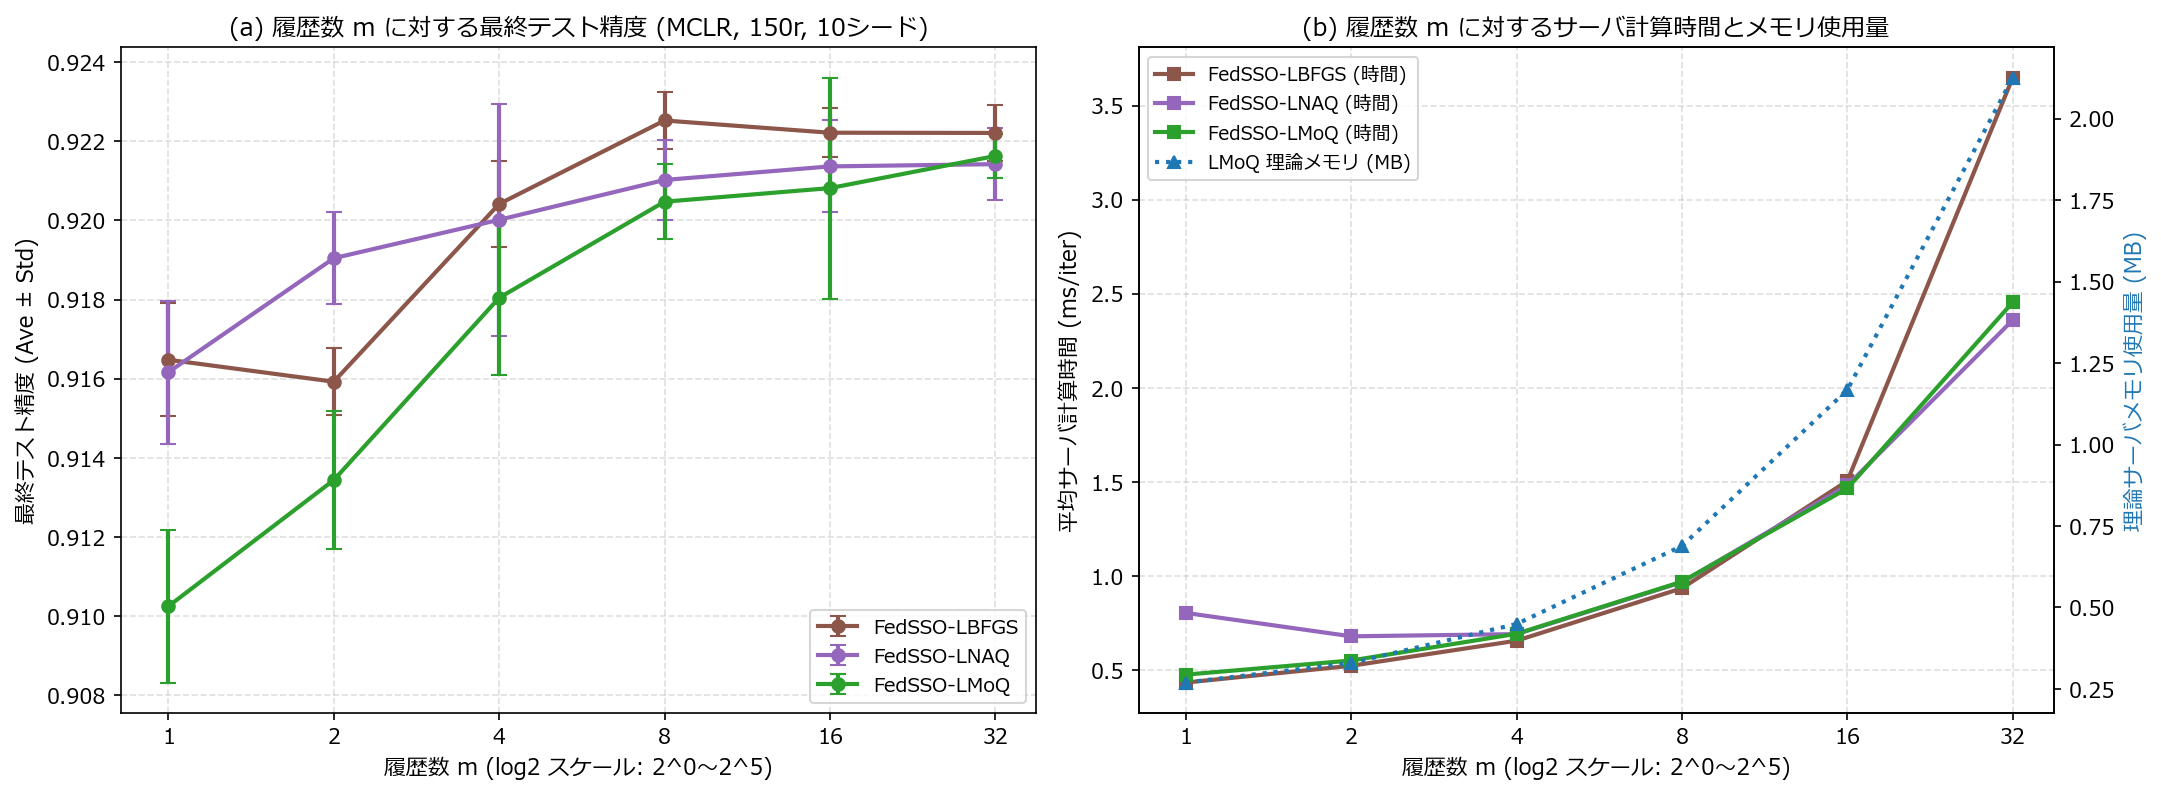

In [5]:
# 図2 (ex003): 記憶制限履歴数 m (2^0..2^5) の影響グラフ
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.4))
c_3b = {"FedSSO-LBFGS": "#8c564b", "FedSSO-LNAQ": "#9467bd", "FedSSO-LMoQ": "#2ca02c"}
m_ticks = [1, 2, 4, 8, 16, 32]
m_labels = ["1", "2", "4", "8", "16", "32"]

for algo in ["FedSSO-LBFGS", "FedSSO-LNAQ", "FedSSO-LMoQ"]:
    sub = df_3b[df_3b["Algorithm"] == algo].sort_values("m")
    axes[0].errorbar(sub["m"], sub["Acc_Ave"], yerr=sub["Acc_Std"], marker="o", capsize=4, linewidth=2.0, color=c_3b[algo], label=algo)
    axes[1].plot(sub["m"], sub["Server_Time_ms"], marker="s", linewidth=2.0, color=c_3b[algo], label=f"{algo} (時間)")

axes[0].set_xscale("log", base=2)
axes[0].set_title("(a) 履歴数 m に対する最終テスト精度 (MCLR, 150r, 10シード)", fontsize=11.5)
axes[0].set_xlabel("履歴数 m (log2 スケール: 2^0〜2^5)", fontsize=10.5)
axes[0].set_ylabel("最終テスト精度 (Ave ± Std)", fontsize=10.5)
axes[0].set_xticks(m_ticks)
axes[0].set_xticklabels(m_labels)
axes[0].set_xlim(0.82, 38)
axes[0].grid(True, linestyle="--", alpha=0.4)
axes[0].legend(loc="lower right", fontsize=9.5)

axes[1].set_xscale("log", base=2)
axes[1].set_title("(b) 履歴数 m に対するサーバ計算時間とメモリ使用量", fontsize=11.5)
axes[1].set_xlabel("履歴数 m (log2 スケール: 2^0〜2^5)", fontsize=10.5)
axes[1].set_ylabel("平均サーバ計算時間 (ms/iter)", fontsize=10.5)
axes[1].set_xticks(m_ticks)
axes[1].set_xticklabels(m_labels)
axes[1].set_xlim(0.82, 38)
axes[1].grid(True, linestyle="--", alpha=0.4)

ax_mem = axes[1].twinx()
sub_lmoq = df_3b[df_3b["Algorithm"] == "FedSSO-LMoQ"].sort_values("m")
ax_mem.plot(sub_lmoq["m"], sub_lmoq["Server_Mem_MB"], marker="^", linestyle=":", linewidth=2.0, color="#1f77b4", label="LMoQ 理論メモリ (MB)")
ax_mem.set_ylabel("理論サーバメモリ使用量 (MB)", fontsize=10.5, color="#1f77b4")
lines1, labels1 = axes[1].get_legend_handles_labels()
lines2, labels2 = ax_mem.get_legend_handles_labels()
axes[1].legend(lines1 + lines2, labels1 + labels2, loc="upper left", fontsize=9)

plt.tight_layout()
plt.savefig("../report/img/ex003_memory_size_impact.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
# 実験 3C: 正定値保証・曲率クリッピングのアブレーション検証 (MoQ系 + NAQ系 全7手法, CNN 100r, 10シード)
df_3c, curves_3c = run_curvature_ablation_study(
    ex2_model, ex2_utils, packed_cnn, X_tr_c, y_tr_c, X_te_c, y_te_c,
    seeds=DEFAULT_SEEDS, rounds=100
)
df_3c.to_csv("../datasets/ex003_curvature_ablation.csv", index=False)
print("=== 実験 3C: 正定値性強制 (曲率クリッピング) アブレーション (CNN, 100r, 10シード) ===")
df_3c

=== 実験 3C: 正定値性強制 (曲率クリッピング) アブレーション (CNN, 100r, 10シード) ===


Exp 3C: Curvature Ablation: 100%|##########| 280/280 [11:42<00:00,  2.51s/it]


,Algorithm,Condition,Acc_Ave,Acc_Med,Acc_Best,Acc_Worst,Acc_Std,MaxAcc_Ave,Loss_Ave,Diverged_Seeds,Clip_Ave,Reset_Ave
0,FedSSO,"標準 (1e-4, 9999)",0.977313,0.978467,0.981209,0.969557,0.003283,0.977627,0.056836,0,1.0,0.5
1,FedSSO,"狭帯域 (1e-2, 500)",0.975680,0.977296,0.980580,0.966815,0.003979,0.977342,0.060117,0,1.0,0.7
2,FedSSO,"過大上限 (1e-4, 1e7)",0.975023,0.976811,0.980695,0.964473,0.005445,0.976731,0.062466,0,1.0,0.4
3,FedSSO,正定値保証なし,0.620784,0.950366,0.975611,0.098000,0.421642,0.648372,0.894197,4,0.0,0.0
4,FedSSO-MoQ,"標準 (1e-4, 9999)",0.973075,0.976639,0.980580,0.954307,0.007625,0.974138,0.071611,0,1.4,0.6
5,FedSSO-MoQ,"狭帯域 (1e-2, 500)",0.973892,0.975354,0.979552,0.963674,0.004920,0.974275,0.067814,0,1.2,0.5
6,FedSSO-MoQ,"過大上限 (1e-4, 1e7)",0.973292,0.975783,0.980523,0.951565,0.008026,0.973549,0.068428,0,1.2,0.5
7,FedSSO-MoQ,正定値保証なし,0.786713,0.954849,0.978924,0.098000,0.341807,0.806711,0.372444,2,0.0,0.0
8,FedSSO-LMoQ,"標準 (1e-4, 9999)",0.890776,0.956077,0.962474,0.303975,0.195681,0.957539,0.414820,0,4.7,0.8
9,FedSSO-LMoQ,"狭帯域 (1e-2, 500)",0.955912,0.958562,0.962017,0.944882,0.005958,0.956151,0.135708,0,9.6,0.1


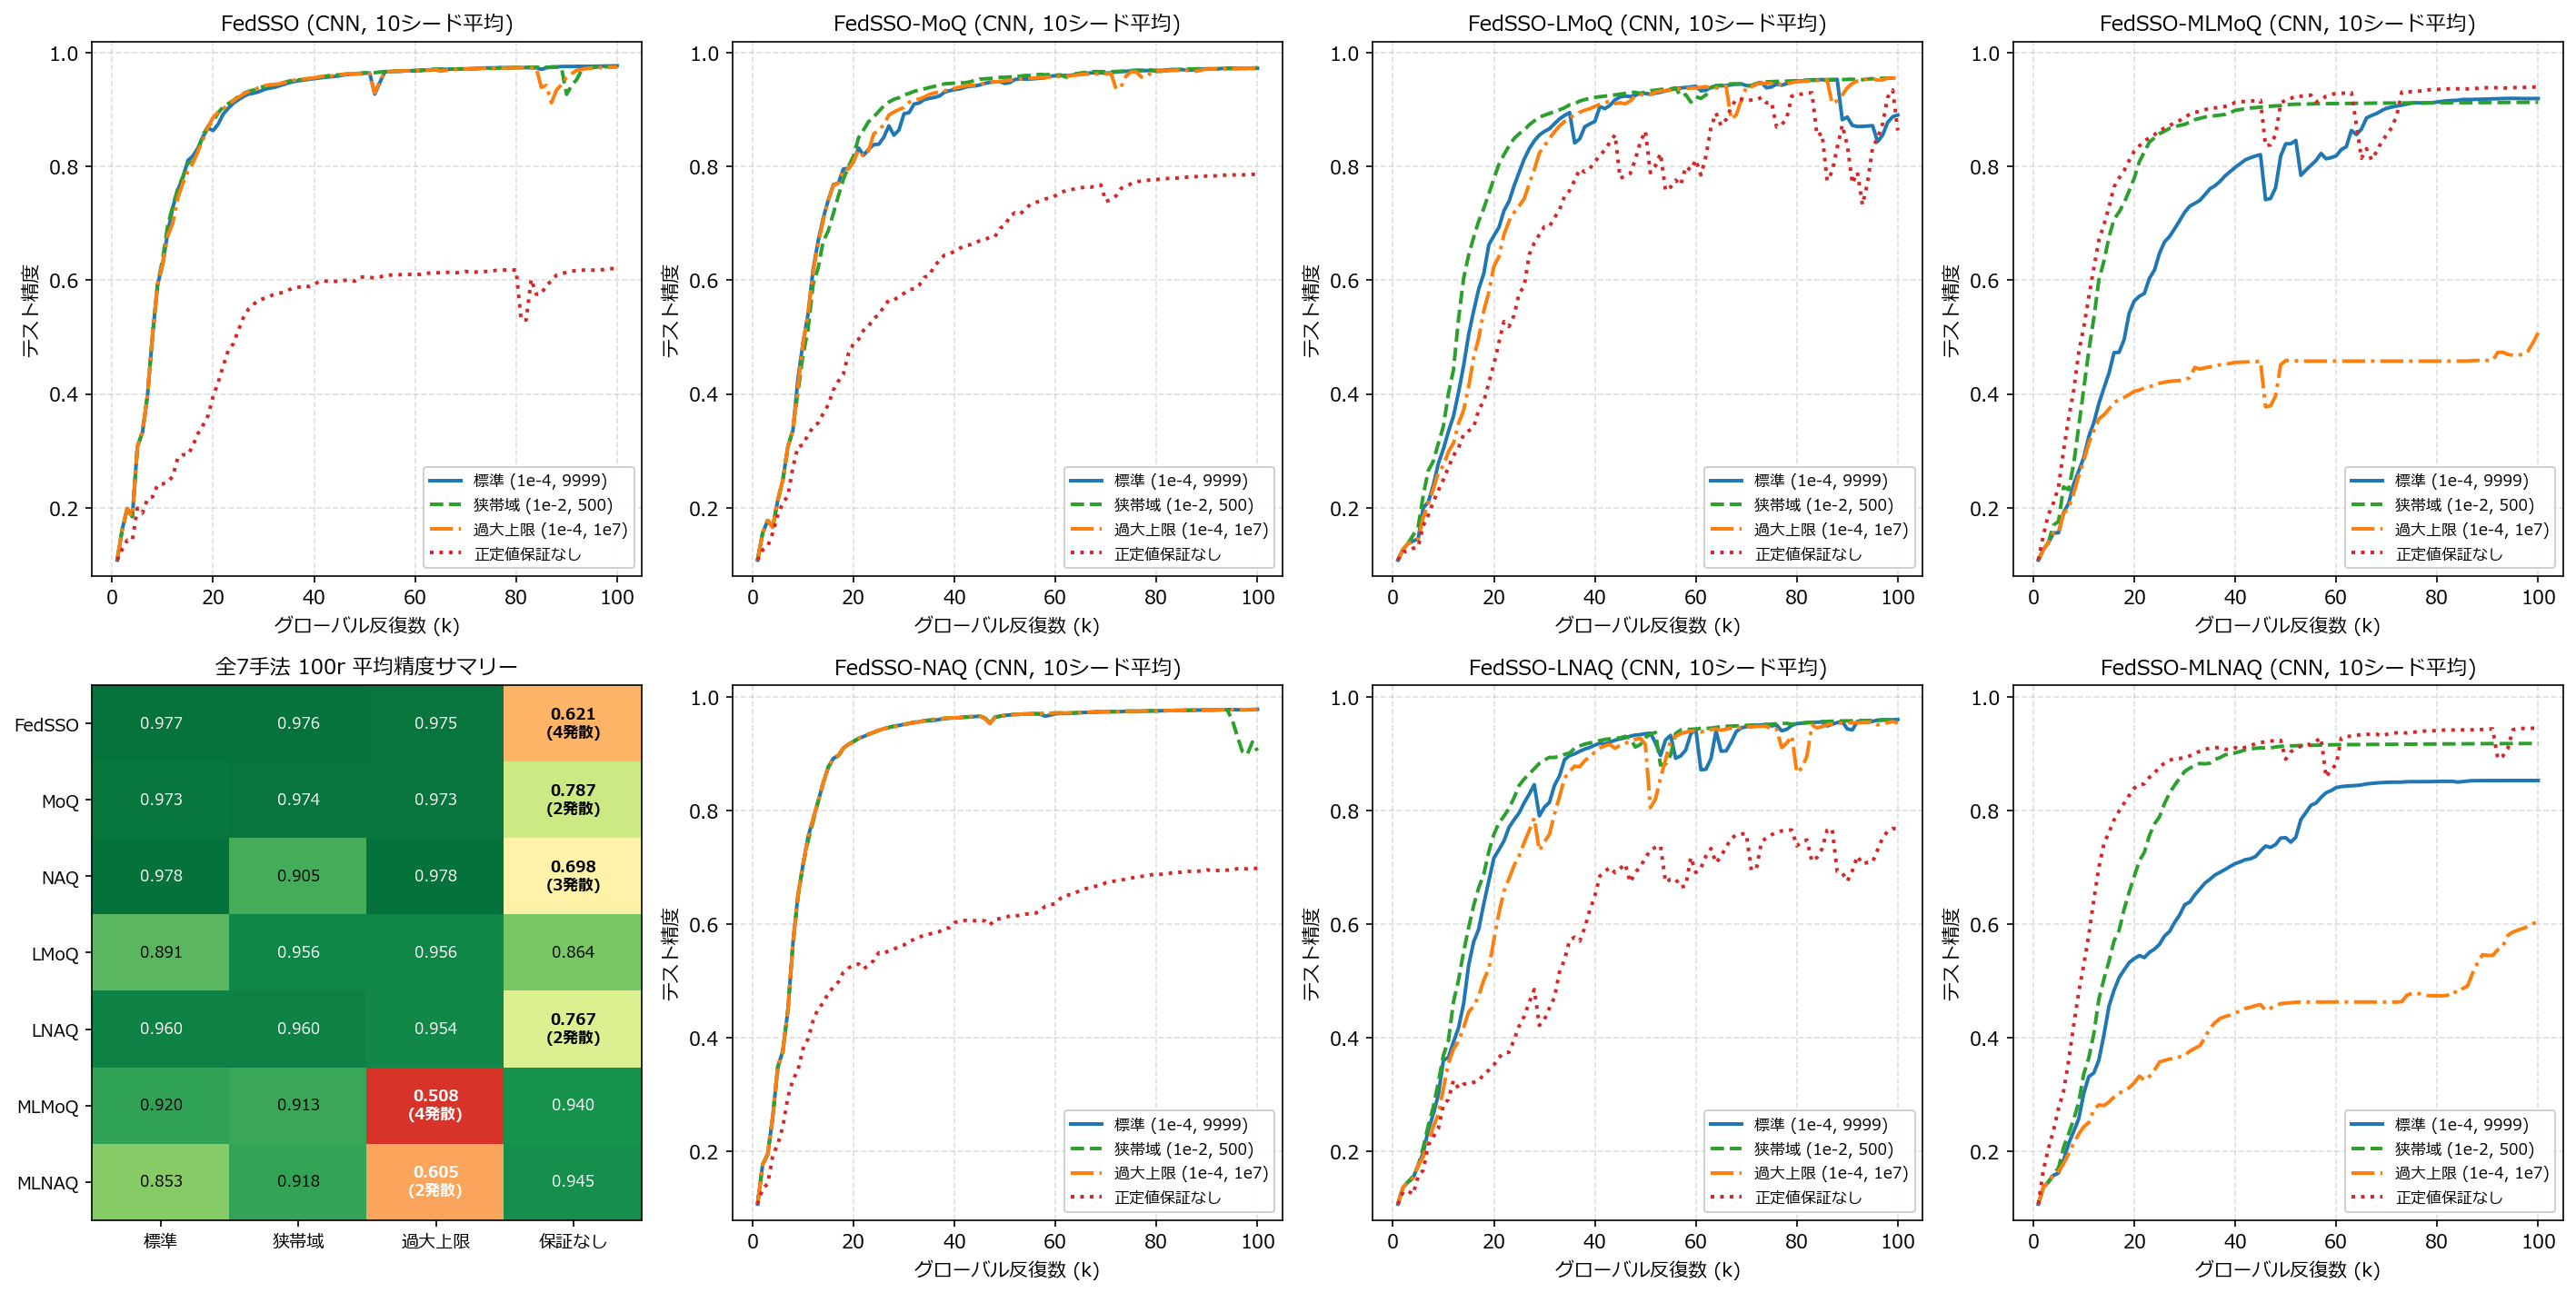

In [7]:
# 図3 (ex003): 曲率クリッピングアブレーション 2x4 統合パネル (上段: MoQ系+FedSSO / 下段: ヒートマップ+NAQ系)
fig, axes = plt.subplots(2, 4, figsize=(19.0, 9.6))
top_algos = ["FedSSO", "FedSSO-MoQ", "FedSSO-LMoQ", "FedSSO-MLMoQ"]
bot_algos = ["FedSSO-NAQ", "FedSSO-LNAQ", "FedSSO-MLNAQ"]
cond_styles = [
    ("標準 (1e-4, 9999)",    "#1f77b4", "-"),
    ("狭帯域 (1e-2, 500)",   "#2ca02c", "--"),
    ("過大上限 (1e-4, 1e7)", "#ff7f0e", "-."),
    ("正定値保証なし",        "#d62728", ":"),
]
x_100 = np.arange(1, 101)

for col_idx, algo in enumerate(top_algos):
    ax = axes[0, col_idx]
    for cond_name, col, ls in cond_styles:
        ax.plot(x_100, curves_3c[f"{algo} | {cond_name}"], label=cond_name, color=col, linestyle=ls, linewidth=1.9)
    ax.set_title(f"{algo} (CNN, 10シード平均)", fontsize=11.0)
    ax.set_xlabel("グローバル反復数 (k)", fontsize=10)
    ax.set_ylabel("テスト精度", fontsize=10)
    ax.set_ylim(0.08, 1.02)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.legend(loc="lower right", fontsize=8.2, framealpha=0.92)

# 下段左 (1,0): 全7手法 x 4条件の平均テスト精度ヒートマップ
ax_hm = axes[1, 0]
hm_algos = ["FedSSO", "FedSSO-MoQ", "FedSSO-NAQ", "FedSSO-LMoQ", "FedSSO-LNAQ", "FedSSO-MLMoQ", "FedSSO-MLNAQ"]
hm_conds = [c[0] for c in cond_styles]
hm_cond_labels = ["標準", "狭帯域", "過大上限", "保証なし"]
mat_acc = np.zeros((len(hm_algos), len(hm_conds)), dtype=np.float64)
mat_div = np.zeros((len(hm_algos), len(hm_conds)), dtype=int)
for i, a in enumerate(hm_algos):
    for j, c_name in enumerate(hm_conds):
        row = df_3c[(df_3c["Algorithm"] == a) & (df_3c["Condition"] == c_name)].iloc[0]
        mat_acc[i, j] = float(row["Acc_Ave"])
        mat_div[i, j] = int(row["Diverged_Seeds"])

im = ax_hm.imshow(mat_acc, cmap="RdYlGn", vmin=0.45, vmax=0.99, aspect="auto")
ax_hm.set_xticks(np.arange(len(hm_cond_labels)))
ax_hm.set_xticklabels(hm_cond_labels, fontsize=9.2)
ax_hm.set_yticks(np.arange(len(hm_algos)))
ax_hm.set_yticklabels([a.replace("FedSSO-", "") for a in hm_algos], fontsize=9.2)
ax_hm.set_title("全7手法 100r 平均精度サマリー", fontsize=11.0)
for i in range(len(hm_algos)):
    for j in range(len(hm_conds)):
        val = mat_acc[i, j]
        div = mat_div[i, j]
        txt = f"{val:.3f}" + (f"\n({div}発散)" if div > 0 else "")
        tcol = "white" if (val < 0.62 or val > 0.93) else "black"
        ax_hm.text(j, i, txt, ha="center", va="center", color=tcol, fontsize=8.0, fontweight="bold" if div > 0 else "normal")

for col_idx, algo in enumerate(bot_algos, start=1):
    ax = axes[1, col_idx]
    for cond_name, col, ls in cond_styles:
        ax.plot(x_100, curves_3c[f"{algo} | {cond_name}"], label=cond_name, color=col, linestyle=ls, linewidth=1.9)
    ax.set_title(f"{algo} (CNN, 10シード平均)", fontsize=11.0)
    ax.set_xlabel("グローバル反復数 (k)", fontsize=10)
    ax.set_ylabel("テスト精度", fontsize=10)
    ax.set_ylim(0.08, 1.02)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.legend(loc="lower right", fontsize=8.2, framealpha=0.92)

plt.tight_layout()
plt.savefig("../report/img/ex003_curvature_ablation.png", dpi=150, bbox_inches="tight")
plt.show()

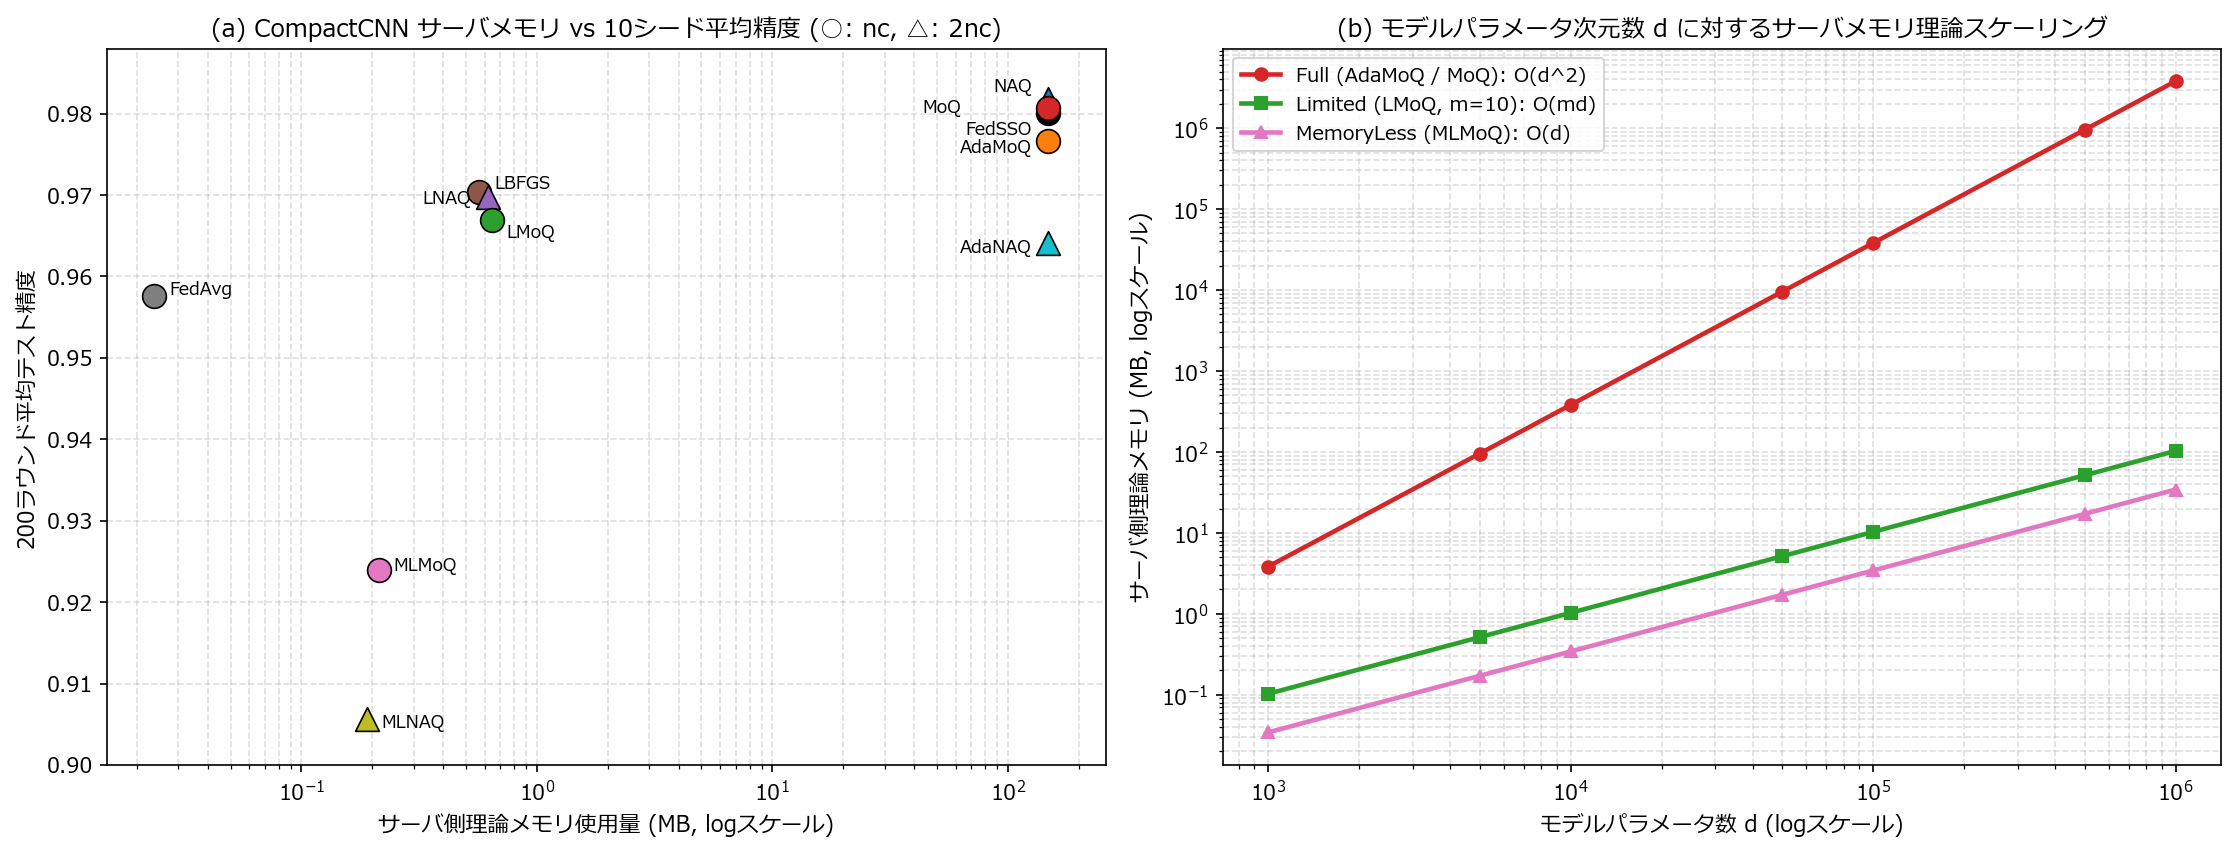

=== 実験 3D: パラメータ次元 d に対する理論メモリ・演算量スケーリング ===
      d  Mem_FedSSO_MB  Mem_AdaMoQ_MB  Mem_LBFGS_MB  Mem_LMoQ_MB  Mem_MLMoQ_MB    Ops_FedSSO    Ops_AdaMoQ  Ops_LMoQ  Ops_MLMoQ
   1000   3.829956e+00   3.841400e+00      0.091553     0.102997      0.034332       6004000       6008000     88000      14000
   5000   9.544373e+01   9.550095e+01      0.457764     0.514984      0.171661     150020000     150040000    440000      70000
  10000   3.816223e+02   3.817368e+02      0.915527     1.029968      0.343323     600040000     600080000    880000     140000
  50000   9.537506e+03   9.538078e+03      4.577637     5.149841      1.716614   15000200000   15000400000   4400000     700000
 100000   3.814850e+04   3.814964e+04      9.155273    10.299683      3.433228   60000400000   60000800000   8800000    1400000
 500000   9.536819e+05   9.536877e+05     45.776367    51.498413     17.166138 1500002000000 1500004000000  44000000    7000000
1000000   3.814713e+06   3.814724e+06     91.552734   102.9

In [8]:
# 実験 3D: 理論スケーリング解析と ex001/ex002 実測に基づくパレート比較
df_scale = compute_theoretical_scaling()
df_scale.to_csv("../datasets/ex003_theoretical_scaling.csv", index=False)
print("=== 実験 3D: パラメータ次元 d に対する理論メモリ・演算量スケーリング ===")
print(df_scale.to_string(index=False))

df_ex1 = pd.read_csv("../datasets/ex001_mclr_summary.csv")
df_ex2 = pd.read_csv("../datasets/ex002_cnn_summary.csv")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))
color_map = {
    "FedAvg": "#7f7f7f", "FedSSO": "#000000", "FedSSO-NAQ": "#1f77b4", "FedSSO-MoQ": "#d62728",
    "FedSSO-AdaNAQ": "#17becf", "FedSSO-AdaMoQ": "#ff7f0e", "FedSSO-LBFGS": "#8c564b",
    "FedSSO-LNAQ": "#9467bd", "FedSSO-LMoQ": "#2ca02c", "FedSSO-MLNAQ": "#bcbd22", "FedSSO-MLMoQ": "#e377c2",
}
label_offsets = {
    "FedAvg": (7, 3, "left"),
    "FedSSO": (-8, -8, "right"),
    "FedSSO-NAQ": (-8, 6, "right"),
    "FedSSO-MoQ": (-42, 0, "right"),
    "FedSSO-AdaNAQ": (-8, -2, "right"),
    "FedSSO-AdaMoQ": (-8, -3, "right"),
    "FedSSO-LBFGS": (7, 4, "left"),
    "FedSSO-LNAQ": (-8, -1, "right"),
    "FedSSO-LMoQ": (7, -6, "left"),
    "FedSSO-MLNAQ": (7, -2, "left"),
    "FedSSO-MLMoQ": (7, 2, "left"),
}
for _, row in df_ex2.iterrows():
    a = row["Algorithm"]
    mem = row["Server_Mem_MB"]
    acc = row["Acc_Ave"]
    comm = row["Comm_Per_Iter"]
    marker = "^" if comm > 1.5 else "o"
    axes[0].scatter(mem, acc, s=130, color=color_map[a], marker=marker, edgecolors="black", linewidth=0.8, zorder=3)
    label_short = a.replace("FedSSO-", "")
    dx, dy, ha_align = label_offsets[a]
    axes[0].annotate(label_short, (mem, acc), xytext=(dx, dy),
                     textcoords="offset points", ha=ha_align, va="center", fontsize=8.5)

axes[0].set_xscale("log")
axes[0].set_xlim(0.015, 260)
axes[0].set_ylim(0.900, 0.988)
axes[0].set_title("(a) CompactCNN サーバメモリ vs 10シード平均精度 (○: nc, △: 2nc)", fontsize=11.5)
axes[0].set_xlabel("サーバ側理論メモリ使用量 (MB, logスケール)", fontsize=10.5)
axes[0].set_ylabel("200ラウンド平均テスト精度", fontsize=10.5)
axes[0].grid(True, which="both", linestyle="--", alpha=0.4)

axes[1].plot(df_scale["d"], df_scale["Mem_AdaMoQ_MB"], marker="o", linewidth=2.2, color="#d62728", label="Full (AdaMoQ / MoQ): O(d^2)")
axes[1].plot(df_scale["d"], df_scale["Mem_LMoQ_MB"], marker="s", linewidth=2.2, color="#2ca02c", label="Limited (LMoQ, m=10): O(md)")
axes[1].plot(df_scale["d"], df_scale["Mem_MLMoQ_MB"], marker="^", linewidth=2.2, color="#e377c2", label="MemoryLess (MLMoQ): O(d)")
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_title("(b) モデルパラメータ次元数 d に対するサーバメモリ理論スケーリング", fontsize=11.5)
axes[1].set_xlabel("モデルパラメータ数 d (logスケール)", fontsize=10.5)
axes[1].set_ylabel("サーバ側理論メモリ (MB, logスケール)", fontsize=10.5)
axes[1].grid(True, which="both", linestyle="--", alpha=0.4)
axes[1].legend(loc="upper left", fontsize=9.5)

plt.tight_layout()
plt.savefig("../report/img/ex003_pareto_scalability.png", dpi=150, bbox_inches="tight")
plt.show()